# 03 · Deep learning: RoBERTa-base fine-tuning (replay of the original 40 runs + re-run on a GPU)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SheridanLu/detecting-the-detector/blob/main/notebooks/03_dl_roberta.ipynb)

**Goal.** Fine-tune RoBERTa, a pretrained language model, to tell human essays from AI essays, once for each of
the four training sets (arms A-D), and measure how often it wrongly flags real essays by non-native writers (TOEFL)
as AI. Then check that a re-run on Colab gives the same picture as the original run on the A40 server.

> **What is REPLAYED and what is RE-RUN in this notebook**
> * **REPLAYED (section 2, every mode):** the full archived result of the original A40 run, all 4 arms x 5 seeds,
>   recomputed from the saved per-essay scores in `data/preds/roberta/` (40 files). No model is run for this part.
>   It is checked against the archived tables in `data/results/`.
> * **RE-RUN (sections 3-6):** RoBERTa is really fine-tuned and really scores the test essays in this session.
>   SMOKE: a tiny version (CPU is fine). FAST: arms A and C, seed 0, full size, needs a GPU. FULL: all 20 runs.
> * **COMPARED (section 6, FAST/FULL only):** re-run numbers vs archived numbers, with PASS/FAIL per number.

| Mode | What is re-run | Time | GPU |
|---|---|---|---|
| SMOKE | arms A and C, seed 0, only 64 training essays (32 human + 32 AI), essays cut to 64 tokens, 1 epoch; scores 1,575 essays (Liang test set, LOCNESS, validation set). Tests that the code works; its numbers mean nothing. | about 1-2 min on a laptop CPU, plus the one-off 0.5 GB model download | no |
| FAST (default) | arms A and C, seed 0, all 8,000 training essays, 512 tokens, 2 epochs; scores all 14,272 essays | Colab T4: **ESTIMATE only**, about 30-50 min (not measured, see section 4) | yes |
| FULL | arms A, B, C, D x seeds 0-4 = 20 runs, the paper setting | Colab T4: **estimate** 5-8.5 h (not measured); longer than one free Colab session is guaranteed to last, so finished runs are saved and skipped on restart | yes |

On Colab choose *Runtime > Change runtime type > T4 GPU* before *Run all*. Without a GPU, FAST and FULL fall back to
SMOKE (training 20 runs on a CPU would take days).

> **Status of this notebook (honest):** the outputs saved below are from a **SMOKE run on a laptop CPU**. The FAST and
> FULL re-training has **not been executed on any GPU** (no T4, no other CUDA GPU). A FAST attempt on an Apple laptop
> GPU was stopped before it finished because it was too slow; no result from it is used or shown here. All T4 times
> in this notebook are estimates.

In [1]:
# --- Setup: find the repository (or download it on Colab) and install anything Colab does not have ---
import os, sys, time, pathlib, subprocess
T0 = time.time()
REPO_URL = "https://github.com/SheridanLu/detecting-the-detector"

def _is_repo(p):
    return (p / "ddlib" / "__init__.py").is_file() and (p / "data").is_dir()

def _locate_or_fetch():
    here = pathlib.Path.cwd().resolve()
    for p in [pathlib.Path(os.environ.get("DD_REPO", here)), here, *here.parents]:
        if _is_repo(p):
            return p                                   # mode 1: already inside the repo
    dest = pathlib.Path("/content" if os.path.isdir("/content") else here) / "detecting-the-detector"
    if not _is_repo(dest) and not dest.exists():       # mode 2: git clone (token optional, for a private repo)
        tok = os.environ.get("GH_TOKEN")
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN") or tok
        except Exception:
            pass
        url = REPO_URL.replace("https://", f"https://x-access-token:{tok}@") if tok else REPO_URL
        subprocess.run(["git", "clone", "--depth", "1", "-q", url, str(dest)], env=dict(os.environ, GIT_TERMINAL_PROMPT="0"))
        if tok and dest.exists():
            subprocess.run(["git", "-C", str(dest), "remote", "set-url", "origin", REPO_URL])   # token not kept on disk
    if _is_repo(dest):
        return dest
    return None                                        # mode 3 (zip upload) is handled by ddlib below

root = _locate_or_fetch()
if root is None:
    # Zip fallback: needs the small ddlib/paths.py helper, which we cannot import yet, so do it here.
    print("Could not find or clone the repository.\n"
          "Fix 1: add a Colab secret GH_TOKEN (key icon, left sidebar) with read access, allow notebook access, re-run.\n"
          f"Fix 2: download the repo as a zip ({REPO_URL} > Code > Download ZIP) and upload it when asked.")
    from google.colab import files
    import zipfile
    up = files.upload()
    zipfile.ZipFile(next(k for k in up if k.endswith(".zip"))).extractall("/content")
    root = next(p.parent.parent for p in pathlib.Path("/content").glob("*/ddlib/__init__.py") if _is_repo(p.parent.parent))
sys.path.insert(0, str(root))
os.chdir(root)                                         # all paths below are relative to the repo root

_req = [l.strip() for l in open("requirements-colab.txt") if l.strip() and not l.startswith("#")]
if _req:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_req], check=True)

from ddlib import get_repo
REPO = get_repo()
print("Python", sys.version.split()[0])

# Notebook 03 also needs torch and transformers. Colab has both; install a pinned version only if one is missing.
import importlib.util, re
_need = [l.strip() for l in open("requirements-nb03.txt") if l.strip() and not l.startswith("#")]
_missing = [l for l in _need if importlib.util.find_spec(re.split(r"[=<>!~ \[]", l)[0]) is None]
if _missing:
    print("Installing:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
import torch, transformers
print("torch", torch.__version__, "| transformers", transformers.__version__, "| CUDA GPU:", torch.cuda.is_available())

Repository found. Data folder present: True
Python 3.12.16


torch 2.9.1 | transformers 5.22.2 | CUDA GPU: False


## Configuration

In [2]:
# --- CONFIG ---------------------------------------------------------------------------------------
# MODE = "SMOKE" (tiny, CPU is fine; used for automated testing), "FAST" (default, needs a GPU) or "FULL" (paper setting).
# Change the string below to switch. (The DD_MODE environment variable is only used by automated tests.)
MODE = os.environ.get("DD_MODE", "FAST").upper()
assert MODE in ("SMOKE", "FAST", "FULL"), MODE
ALLOW_CPU_TRAINING = False   # True = really train FAST/FULL on a CPU (days). Otherwise they fall back to SMOKE.
PRECISION = "auto"           # auto: fp16 on a T4, bf16 on newer GPUs (as the original A40 run), fp32 on CPU / Apple GPU

from ddlib import dl_roberta as R
DEVICE, PREC = R.device_and_precision(PRECISION, force_device=os.environ.get("DD_DEVICE"))   # DD_DEVICE: tests only
if MODE != "SMOKE" and DEVICE == "cpu" and not ALLOW_CPU_TRAINING:
    print(f"*** No GPU found. {MODE} would take days on a CPU, so this session runs SMOKE instead. ***\n"
          "*** On Colab: Runtime > Change runtime type > T4 GPU, then Run all again.             ***")
    MODE = "SMOKE"

ARMS = "ABCD" if MODE == "FULL" else "AC"
SEEDS = [0, 1, 2, 3, 4] if MODE == "FULL" else [0]
RUNS = [(arm, s) for s in SEEDS for arm in ARMS]       # seed by seed, so an interrupted FULL run has whole seeds done
LR, BATCH = R.PAPER["lr"], R.PAPER["batch_size"]        # 2e-5 and 16, as in a40/train_roberta.py
if MODE == "SMOKE":
    TRAIN_PER_CLASS, MAX_LEN, EPOCHS = 32, 64, 1         # 32 human + 32 AI essays, 64 tokens, 1 pass
else:
    TRAIN_PER_CLASS, MAX_LEN, EPOCHS = None, R.PAPER["max_len"], R.PAPER["epochs"]   # all 8,000 essays, 512 tokens, 2 epochs
SCORE_BATCH = 64 if DEVICE == "cuda" else 32

# Where finished runs are saved. On Colab in FULL mode: your Google Drive, because a free Colab machine and its disk
# are deleted when the session ends; a restarted FULL run then skips every run already saved there.
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = IN_COLAB and MODE == "FULL"
RESUME = MODE != "SMOKE"     # SMOKE always re-trains (it is quick and is meant to test the code)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RUN_DIR = pathlib.Path("/content/drive/MyDrive/detecting-the-detector-runs/roberta") / MODE
else:
    RUN_DIR = pathlib.Path("outputs/roberta_rerun") / MODE
print(f"MODE = {MODE} | runs to train: {len(RUNS)} (" + ", ".join(f"arm {a} seed {s}" for a, s in RUNS) + ")")
print(f"device: {R.device_name(DEVICE)} | precision: {PREC} | essays cut at {MAX_LEN} tokens | epochs {EPOCHS} | "
      f"batch {BATCH} | learning rate {LR}")
print("finished runs are saved in:", RUN_DIR, "| skip runs finished earlier:", RESUME)

MODE = SMOKE | runs to train: 2 (arm A seed 0, arm C seed 0)
device: CPU (arm64, 15 threads) | precision: fp32 | essays cut at 64 tokens | epochs 1 | batch 16 | learning rate 2e-05
finished runs are saved in: outputs/roberta_rerun/SMOKE | skip runs finished earlier: False


## 1. What this notebook does, in plain words

**Fine-tuning.** RoBERTa-base is a language model (125 million numbers, "weights") that was already trained by its
authors to understand English by reading a huge amount of text. *Fine-tuning* means we add a small new output layer
with two answers (human / AI) and then continue training *all* the weights for a short while on our labelled essays:
the model reads 16 essays, guesses, is told the right answers, and every weight is nudged a little so that the
next guess is better. After 2 passes over the 8,000 training essays (1,000 nudges) the model outputs, for any
essay, a probability that it is AI-written. An essay is **flagged as AI** if that probability is at least 0.5.

**Why four training sets (arms).** All four use the same 4,000 AI essays and 4,000 human essays; only *which*
human essays changes:

| arm | human essays the detector learns from |
|---|---|
| A | native US students only |
| B | half native, half school-age non-native students |
| C | half native, half exam essays by non-native adults (the kind of writing TOEFL essays are) |
| D (control) | half native, half *other* native writing - tests whether C helps just because it adds variety |

If the detector wrongly flags non-native writers because it never saw their writing, then arm C (and less so B)
should flag fewer TOEFL essays than A, and more clearly so than the control D.

**The settings** are copied from the original script `a40/train_roberta.py` and were **not tuned** (no search over
learning rates etc.); unchanged library defaults fill in the rest. Details in `ddlib/dl_roberta.py`.

| setting | value |
|---|---|
| model | `roberta-base` from huggingface.co, every weight trained ("full fine-tune") |
| learning rate | 2e-5, decreasing linearly to 0, no warm-up |
| batch size | 16 essays per step |
| epochs (passes over the data) | 2 (all arms; every arm has 8,000 essays) |
| max length | 512 tokens (roughly 380 words); longer essays are cut |
| optimiser | AdamW, no weight decay, gradients clipped at 1.0 |
| number format | original: bf16 on an NVIDIA A40. Here: fp16 on a T4 (no fast bf16), fp32 on CPU / Apple GPU |
| seeds | 0-4 (the seed fixes the random start of the new output layer and the order of the essays) |

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from ddlib import data as D, metrics as M, plots as P
from ddlib import clean
from ddlib.overlap import build_index, count_overlap
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
train_ids = D.train_exam_ids()          # FCE / W&I essays that arm C trains on; removed from every evaluation

def pct_sd(s, scale=100, nd=1):
    # 'mean ± SD' over seeds (just the value if there is one seed)
    return f"{s.mean() * scale:.{nd}f}" + (f" ± {s.std() * scale:.{nd}f}" if len(s) > 1 else "")

HEAD = {"FP_TOEFL": "TOEFL flagged %", "FP_Hewlett": "familiar native flagged %",
        "FP_nativeOOD_mean": "unfamiliar native flagged %", "flag90_TOEFL": "TOEFL flagged % (90%-detection thr.)",
        "bias_TOEFLvsHewlett": "bias AUC TOEFL vs Hewlett"}
PRF = {"precision": "precision", "recall": "recall", "f1": "F1", "accuracy": "accuracy"}

def headline_table(runs):
    t = {}
    for k, v in HEAD.items():
        t[v] = runs.groupby("arm")[k].apply(lambda s: pct_sd(s, 1 if k.startswith("bias") else 100, 3 if k.startswith("bias") else 1))
    for k, v in PRF.items():
        t[v] = runs.groupby("arm")[k].apply(lambda s: pct_sd(s, 1, 3))
    return pd.DataFrame(t)

## 2. REPLAYED: the archived result of the original run (all 4 arms x 5 seeds)

Everything in this section is **REPLAYED**: it is computed from the per-essay scores that the 40 original RoBERTa
runs saved on the A40 server (`data/preds/roberta/`: 20 main runs = 4 arms x 5 seeds with 8,000 training essays,
plus 20 learning-curve runs of arms A/B with 1,000 and 2,000 essays per class). No model is trained or run here, so
this section shows the full archived result in every mode, also in SMOKE.

**How to read the numbers.** The *positive* class is "AI".
* **False-flag rate** (`... flagged %`): of the *human* essays in a group, the share the detector calls AI. Lower is
  better. Groups: **TOEFL** = 91 real TOEFL essays by non-native writers (Liang et al. 2023); **familiar native** =
  88 US 8th-grade essays (Hewlett), similar to the native essays in training; **unfamiliar native** = average over
  three native sets unlike the training data (college-application essays, Stanford CS224N essays, LOCNESS).
* **TOEFL flagged at the 90%-detection threshold**: the pre-registered primary measure. Instead of 0.5, each run uses
  the threshold at which it catches 90% of the AI essays in the validation set.
* **Bias AUC**: chance that a random TOEFL essay gets a more AI-like score than a random Hewlett essay. 0.5 = no bias,
  1.0 = every TOEFL essay looks more AI-like than every native one.
* On the **Liang test set** (394 human essays: TOEFL 91, Hewlett 88, college 70, CS224N 145; and 352 GPT-3 essays):
  **precision** = of the essays flagged as AI, the share that really are AI (low precision = many humans wrongly
  accused); **recall** = of the AI essays, the share that is caught; **F1** = one number combining the two (their
  harmonic mean; 1.0 is perfect); **accuracy** = share of all essays classified correctly. Threshold 0.5.

What to look at: the TOEFL column going down from A to C, while the control D stays high; and whether F1 improves.

In [4]:
t = time.time()
rows, lc_rows = [], []
for arm, seed, n in sorted(D.available_runs("RoBERTa")):
    p = D.load_preds("RoBERTa", arm, seed, n)
    if n == 4000:
        rows.append(dict(arm=arm, seed=seed, run=D.run_name(arm, seed, n), **M.run_row(p, train_ids), **M.liang_prf_from_scores(p)))
    else:
        lc_rows.append(dict(arm=arm, seed=seed, n=n, FP_TOEFL=M.flag_rate(p[p.corpus == M.TOEFL].score)))
ARCH = pd.DataFrame(rows)              # archived runs, recomputed from the saved scores: 4 arms x 5 seeds
LC = pd.DataFrame(lc_rows)
print(f"REPLAYED from {len(rows) + len(lc_rows)} saved prediction files ({len(rows)} main runs, {len(lc_rows)} learning-curve runs) "
      f"in {time.time() - t:.1f} s")

# Self-check: the replay must equal the tables the original run computed (data/results/). Tolerance 1e-9.
CM = ARCH.groupby("arm")[[c for c in ARCH.columns if c.startswith(("FP_", "TPR_", "AUC_", "bias_"))]].mean()
CM["TOEFL_sd"] = ARCH.groupby("arm").FP_TOEFL.std()
old_cm = D.load_result("model_comparison_all"); old_cm = old_cm[old_cm.model == "RoBERTa"]
c1 = M.compare_frames(CM.reset_index(), old_cm, [c for c in CM.columns if c in old_cm.columns], ["arm"])
old_fu = D.load_result("followup_runs_roberta").rename(columns={"P1_toefl_flag90": "flag90_TOEFL", "bias_auc_vs_hewlett": "bias_TOEFLvsHewlett",
            "P3_arguGPT_vs_toefl": "AUC_ArguGPTvsTOEFL", "native_ood_mean90": "flag90_nativeOOD_mean", "thr": "thr_tpr90"})
c2 = M.compare_frames(ARCH, old_fu, ["thr_tpr90", "flag90_TOEFL", "bias_TOEFLvsHewlett", "AUC_ArguGPTvsTOEFL", "flag90_nativeOOD_mean"], ["arm", "seed"])
old_prf = D.load_result("prf1_runs"); old_prf = old_prf[old_prf.model == "RoBERTa"]
c3 = M.compare_frames(ARCH, old_prf, ["accuracy", "precision", "recall", "f1", "false_flag_rate", "f1_bal_TOEFL", "f1_bal_Hewlett"], ["run"])
agg = D.load_result("metrics_agg"); agg = agg[agg.model == "RoBERTa"].assign(n=lambda d: d.n.astype(int))
lc_new = pd.concat([LC, ARCH.assign(n=4000)[["arm", "seed", "n", "FP_TOEFL"]]]).groupby(["arm", "n"]).FP_TOEFL.mean().reset_index()
c4 = M.compare_frames(lc_new.rename(columns={"FP_TOEFL": "rate"}),
                      agg[["arm", "n", "rate_t05_TOEFL_real_91__mean"]].rename(columns={"rate_t05_TOEFL_real_91__mean": "rate"}), ["rate"], ["arm", "n"])
checks = pd.DataFrame([
    dict(archived_table="model_comparison_all.csv (RoBERTa rows: flag rates, AUCs, TOEFL SD)", rows=int(c1.rows_compared.max()), columns=len(c1), largest_diff=c1.max_abs_diff.max(), result="PASS" if (c1.result == "PASS").all() and len(c1) else "FAIL"),
    dict(archived_table="followup_runs_roberta.csv (per run: 90% threshold, primary endpoints)", rows=int(c2.rows_compared.max()), columns=len(c2), largest_diff=c2.max_abs_diff.max(), result="PASS" if (c2.result == "PASS").all() and len(c2) else "FAIL"),
    dict(archived_table="prf1_runs.csv (RoBERTa rows: accuracy, precision, recall, F1)", rows=int(c3.rows_compared.max()), columns=len(c3), largest_diff=c3.max_abs_diff.max(), result="PASS" if (c3.result == "PASS").all() and len(c3) else "FAIL"),
    dict(archived_table="metrics_agg.csv (learning curve, TOEFL flagged, arms A/B x 3 sizes)", rows=int(c4.rows_compared.max()), columns=len(c4), largest_diff=c4.max_abs_diff.max(), result="PASS" if (c4.result == "PASS").all() and len(c4) else "FAIL")])
display(checks)
assert (checks.rows > 0).all()
print("REPLAY CHECK:", "PASS" if (checks.result == "PASS").all() else "FAIL",
      "- the replayed numbers below are the archived numbers of the original run (tolerance 1e-9).")

REPLAYED from 40 saved prediction files (20 main runs, 20 learning-curve runs) in 0.5 s


,archived_table,rows,columns,largest_diff,result
0,model_comparison_all.csv (RoBERTa rows: flag r...,4,21,2.220446e-16,PASS
1,followup_runs_roberta.csv (per run: 90% thresh...,20,5,0.000000e+00,PASS
2,"prf1_runs.csv (RoBERTa rows: accuracy, precisi...",20,7,0.000000e+00,PASS
3,"metrics_agg.csv (learning curve, TOEFL flagged...",6,1,0.000000e+00,PASS


REPLAY CHECK: PASS - the replayed numbers below are the archived numbers of the original run (tolerance 1e-9).


In [5]:
print("REPLAYED - original A40 run, mean ± SD over 5 seeds, rates in % at threshold 0.5 unless stated")
display(headline_table(ARCH))
print("REPLAYED - TOEFL essays flagged as AI (%), one value per seed: the seed-to-seed spread")
per_seed = ARCH.pivot(index="seed", columns="arm", values="FP_TOEFL") * 100
per_seed.loc["range (max-min)"] = per_seed.max() - per_seed.min()
display(per_seed.round(1))
print("REPLAYED - learning curve, TOEFL flagged % (mean of 5 seeds) by human/AI essays per class in training")
display((lc_new.pivot(index="n", columns="arm", values="FP_TOEFL") * 100).round(1).astype(object).fillna("-")
        .rename_axis(index="essays per class"))

REPLAYED - original A40 run, mean ± SD over 5 seeds, rates in % at threshold 0.5 unless stated


,TOEFL flagged %,familiar native flagged %,unfamiliar native flagged %,TOEFL flagged % (90%-detection thr.),bias AUC TOEFL vs Hewlett,precision,recall,F1,accuracy
arm,,,,,,,,,
A,98.7 ± 1.8,1.6 ± 1.0,68.7 ± 2.5,66.2 ± 13.2,0.999 ± 0.001,0.542 ± 0.003,1.000 ± 0.000,0.703 ± 0.003,0.602 ± 0.005
B,94.1 ± 2.5,0.2 ± 0.5,70.2 ± 1.6,63.3 ± 9.6,0.999 ± 0.001,0.547 ± 0.003,1.000 ± 0.000,0.707 ± 0.002,0.609 ± 0.004
C,26.2 ± 7.6,0.5 ± 0.6,45.3 ± 4.7,9.7 ± 2.4,0.698 ± 0.082,0.673 ± 0.025,0.997 ± 0.004,0.803 ± 0.017,0.769 ± 0.025
D,90.5 ± 7.3,2.0 ± 2.3,29.1 ± 5.4,57.8 ± 2.3,0.992 ± 0.005,0.680 ± 0.032,0.973 ± 0.021,0.800 ± 0.018,0.769 ± 0.028


REPLAYED - TOEFL essays flagged as AI (%), one value per seed: the seed-to-seed spread


arm,A,B,C,D
seed,,,,
0,96.7,94.5,16.5,89.0
1,100.0,94.5,24.2,79.1
2,100.0,92.3,28.6,97.8
3,96.7,91.2,37.4,91.2
4,100.0,97.8,24.2,95.6
range (max-min),3.3,6.6,20.9,18.7


REPLAYED - learning curve, TOEFL flagged % (mean of 5 seeds) by human/AI essays per class in training


arm,A,B,C,D
essays per class,,,,
1000,96.9,94.7,-,-
2000,94.9,90.8,-,-
4000,98.7,94.1,26.2,90.5


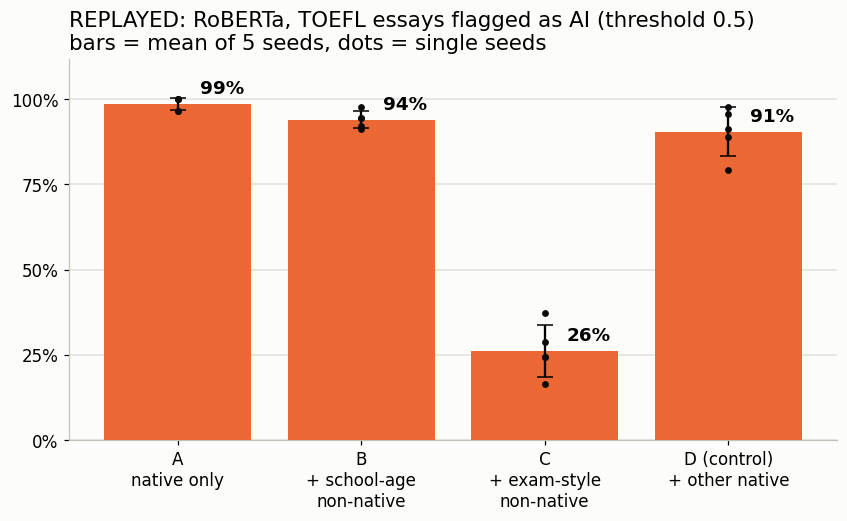

In [6]:
P.setup()
fig, ax = plt.subplots(figsize=(9, 4.5))
m = ARCH.groupby("arm").FP_TOEFL.agg(["mean", "std"]) * 100
ax.bar(range(4), m["mean"], yerr=m["std"], color=P.C_RB, capsize=5, zorder=3)
for i, a in enumerate("ABCD"):
    ax.scatter([i] * 5, ARCH[ARCH.arm == a].FP_TOEFL * 100, color=P.INK, s=12, zorder=4)
    ax.text(i + 0.12, m["mean"].iloc[i] + 3, f"{m['mean'].iloc[i]:.0f}%", fontweight="bold")
ax.set_xticks(range(4)); ax.set_xticklabels([P.ARM_LABELS[a] for a in "ABCD"]); P._pct_axis(ax, 112)
ax.set_title("REPLAYED: RoBERTa, TOEFL essays flagged as AI (threshold 0.5)\nbars = mean of 5 seeds, dots = single seeds", loc="left")
plt.show()

**What the replay shows.** Trained only on native essays (A), RoBERTa flags almost every real TOEFL essay as AI
(about 99%). Adding school-age non-native essays (B) barely helps (about 94%). Adding exam-style non-native
essays (C) brings it down to about 26%, but with a large spread between seeds (about 17% to 37%). The control D
(other native writing) stays high (about 91%), so C's improvement is not just "more variety". F1 on the Liang test
set rises from about 0.70 (A) to 0.80 (C). Familiar native essays are almost never flagged in any arm.

## 3. RE-RUN, step 1: the same data and the same text cleaning as the original

The re-run uses exactly the files the original run used: arms A and B take their training essays from
`data/splits/pool.parquet` by the saved id lists (`manifests.json`), arms C and D use the saved training sets in
`data/followup/trainsets/`, and the essays to score are every test essay plus the 600 validation essays
(`ddlib.data.score_frame()`, same row order as the saved predictions). Every text goes through the same `clean()`
as in the original run (`ddlib/textclean.py`, a character-for-character copy of `a40/common.py::clean`).

**Zero-overlap check.** A detector must never be tested on an essay it was trained on. For every training set used
below we look for training essays that are identical to an evaluated test essay (same text after collapsing white
space, or same first 200 characters; rule copied from the original split builder `a40/build_splits.py`, code in
`ddlib/overlap.py`), and do the same for the validation essays. The result must be 0. Two controls show the check can fail: 5 test essays planted into a training set must be found,
and arm C's 2,000 exam essays must be found among the FCE / W&I test essays that are *excluded* from evaluation for
exactly this reason.

In [7]:
t = time.time()
pool = D.load_pool(cleaned=True)
manifests = D.load_manifests()
exams = D.load_exams(cleaned=True)
val = D.load_val(cleaned=True)
score_df = D.score_frame(exams_cleaned=exams, val_cleaned=val)
if MODE == "SMOKE":   # tiny version: Liang test set (E1), LOCNESS and the validation set only
    score_df = score_df[score_df.exam.isin(["E1", "VAL"]) | (score_df.corpus == "LOCNESS_native")].reset_index(drop=True)
train_sets = {D.run_name(a, s): D.load_trainset(D.run_name(a, s), pool_cleaned=pool, manifests=manifests) for a, s in RUNS}
print(f"texts to score per run: {len(score_df):,} | training sets loaded: {len(train_sets)} | took {time.time() - t:.0f} s")

eval_exams = exams[~exams.essay_id.isin(train_ids)]
idx_test = build_index(eval_exams.text)                              # every test essay that is evaluated
idx_excluded = build_index(exams[exams.essay_id.isin(train_ids)].text)
idx_val = build_index(val.text)
ov = []
for run, (X, y) in train_sets.items():
    nf, n2, na = count_overlap(X, idx_test)
    ov.append(dict(training_set=run, essays=len(X), human=len(y) - sum(y), ai=sum(y), same_full_text=nf, same_first_200=n2,
                   overlapping_with_evaluated_test=na, matches_in_excluded_FCE_WI=count_overlap(X, idx_excluded)[2],
                   info_same_first_200_as_validation=count_overlap(X, idx_val)[1]))
ov = pd.DataFrame(ov); display(ov)
val_vs_test = count_overlap(val.text, idx_test)[2]
X0 = next(iter(train_sets.values()))[0]
ctrl = count_overlap(list(X0[:100]) + ["  " + t_.replace(" ", "  ") for t_ in eval_exams.text.iloc[:5]], idx_test)[2]
c_ok = all(r.matches_in_excluded_FCE_WI == (2000 if r.training_set.endswith("_C") else 0) for r in ov.itertuples())
print("Validation essays overlapping with evaluated test essays:", val_vs_test, "(must be 0)")
print("Control 1: 5 test essays planted into a training set (with extra spaces) found ->", ctrl, "(must be 5)")
print("Control 2: arm C training essays found among the excluded FCE / W&I essays ->",
      ", ".join(f"{r.training_set}: {r.matches_in_excluded_FCE_WI}" for r in ov.itertuples()), "(must be 2,000 for C, 0 otherwise)")
ok = ov.overlapping_with_evaluated_test.sum() == 0 and val_vs_test == 0 and ctrl == 5 and c_ok
print("ZERO-OVERLAP CHECK:", "PASS (no training or validation essay is an evaluated test essay; both controls found)" if ok
      else f"FAIL ({ov.overlapping_with_evaluated_test.sum()} overlaps; validation {val_vs_test}; control 1 {ctrl}/5; control 2 {'ok' if c_ok else 'wrong'})")
print("Note (information, not part of the check): the last column counts training essays whose first 200 characters "
      "equal those of a validation essay. These are AI essays generated for the same writing prompt that begin with the "
      "same sentences (full texts differ). The validation set is only used to set the 90%-detection threshold; the "
      "original split builder checked training and validation against the test essays, not against each other.")
assert ok, "zero-overlap check failed"
pm = D.load_preds("RoBERTa", "A", 0)
print("Row order of the score frame equals the saved predictions:",
      bool((pm.essay_id.values == D.score_frame(exams_cleaned=exams, val_cleaned=val).essay_id.values).all()))

texts to score per run: 1,575 | training sets loaded: 2 | took 6 s


,training_set,essays,human,ai,same_full_text,same_first_200,overlapping_with_evaluated_test,matches_in_excluded_FCE_WI,info_same_first_200_as_validation
0,seed0_A_n4000,8000,4000,4000,0,0,0,0,2
1,seed0_C,8000,4000,4000,0,0,0,2000,2


Validation essays overlapping with evaluated test essays: 0 (must be 0)
Control 1: 5 test essays planted into a training set (with extra spaces) found -> 5 (must be 5)
Control 2: arm C training essays found among the excluded FCE / W&I essays -> seed0_A_n4000: 0, seed0_C: 2000 (must be 2,000 for C, 0 otherwise)
ZERO-OVERLAP CHECK: PASS (no training or validation essay is an evaluated test essay; both controls found)
Note (information, not part of the check): the last column counts training essays whose first 200 characters equal those of a validation essay. These are AI essays generated for the same writing prompt that begin with the same sentences (full texts differ). The validation set is only used to set the 90%-detection threshold; the original split builder checked training and validation against the test essays, not against each other.
Row order of the score frame equals the saved predictions: True


## 4. RE-RUN, step 2: fine-tune and score

Each run = one arm with one seed: load the pretrained model, fine-tune it on that arm's 8,000 essays (SMOKE: 64),
then score every test essay. The log prints the training loss (how wrong the model still is on the training essays;
it should fall towards 0) and the time left.

**Run time on a free Colab T4: an ESTIMATE, not a measurement.** We have not run FAST or FULL on a T4 or on any
other GPU. Our rough
estimate: 15-25 training essays per second at 512 tokens with fp16, so 11-18 min to train one run (2 epochs x 8,000
essays) plus 3-5 min to score the 14,272 essays, i.e. **about 15-25 min per run, 30-50 min for FAST and 5-8.5 h
for FULL**. The cell below prints the *measured* time of every finished run on the hardware you are using and a
projection for the remaining runs; trust that over this estimate.

**Disconnections.** A free Colab session can end before FULL is finished (idle time-out, usage limits). Each
finished run is saved straight away (`RUN_DIR` in the CONFIG cell; in FULL mode on Colab that is your Google Drive)
and is skipped when you *Run all* again, so a restart only loses the run that was in progress. If a T4 runs out of
memory, the run restarts with the 16 essays of a step split into smaller pieces (same maths, less memory).

In [8]:
tok = R.load_tokenizer()
score_ids = R.tokenize(tok, score_df.text.tolist(), MAX_LEN)          # the essays to score, tokenized once
RERUN, LOG_ROWS = {}, []
T_RUNS = time.time(); trained_here = 0
for i, (arm, seed) in enumerate(RUNS):
    run = D.run_name(arm, seed)
    settings = dict(model=R.MODEL_NAME, lr=LR, batch_size=BATCH, epochs=EPOCHS, max_len=MAX_LEN,
                    train_per_class=TRAIN_PER_CLASS, scored_rows=len(score_df), precision=PREC)
    if RESUME:
        prev, meta = R.load_finished(RUN_DIR, run, settings)
        if prev is not None:
            RERUN[(arm, seed)] = prev; LOG_ROWS.append({**meta, "this_session": False})
            print(f"[{i + 1}/{len(RUNS)}] {run}: SKIPPED, finished earlier on {meta['device']} ({meta['total_s'] / 60:.1f} min); loaded from {RUN_DIR}")
            continue
    X, y = train_sets[run]
    if TRAIN_PER_CLASS:   # SMOKE: a random 32 human + 32 AI essays of this training set
        rng = np.random.default_rng(seed); ya = np.asarray(y)
        keep = np.r_[rng.choice(np.where(ya == 0)[0], TRAIN_PER_CLASS, replace=False), rng.choice(np.where(ya == 1)[0], TRAIN_PER_CLASS, replace=False)]
        X, y = [X[j] for j in keep], ya[keep].tolist()
    print(f"[{i + 1}/{len(RUNS)}] {run}: fine-tuning on {len(X):,} essays ({sum(y)} AI) on {R.device_name(DEVICE)}, {PREC}")
    t0 = time.time(); micro = BATCH
    while True:
        model = None
        try:
            model = R.load_model(seed, DEVICE)
            info = R.train(model, tok, X, y, seed=seed, device=DEVICE, precision=PREC, lr=LR, batch_size=BATCH,
                           epochs=EPOCHS, max_len=MAX_LEN, micro_batch=micro, log_every=100)
            break
        except RuntimeError as e:
            if not R.is_oom(e) or micro <= 2:
                raise
            del model; R.free_memory(DEVICE); micro //= 2
            print(f"    out of GPU memory: restarting this run with {BATCH // micro} pieces of {micro} essays per step")
    t1 = time.time()
    s = R.score(model, tok, score_ids, device=DEVICE, precision=PREC, batch_size=SCORE_BATCH)
    out = score_df[["exam", "corpus", "essay_id"]].copy(); out["score"] = s; out["model"] = "RoBERTa (re-run)"; out["run"] = run
    meta = dict(run=run, mode=MODE, settings=settings, device=R.device_name(DEVICE), precision=PREC, micro_batch=micro, n_train=len(X),
                train_s=round(info["train_s"], 1), score_s=round(time.time() - t1, 1), total_s=round(time.time() - t0, 1),
                final_train_loss=round(info["final_loss"], 4), finished=time.strftime("%Y-%m-%d %H:%M:%S"), **R.versions())
    R.save_run(RUN_DIR, run, out, meta)
    RERUN[(arm, seed)] = out; LOG_ROWS.append({**meta, "this_session": True}); trained_here += 1
    del model; R.free_memory(DEVICE)
    left = len(RUNS) - (i + 1)
    print(f"    done: training {info['train_s'] / 60:.1f} min, scoring {len(s):,} essays {meta['score_s'] / 60:.1f} min, "
          f"final training loss {info['final_loss']:.3f}; saved")
    if left and MODE != "SMOKE":
        print(f"    projection from this measured run: {left} run(s) left x {meta['total_s'] / 60:.0f} min = about "
              f"{left * meta['total_s'] / 3600:.1f} h on {R.device_name(DEVICE)}")
RUNLOG = pd.DataFrame(LOG_ROWS)
display(RUNLOG[["run", "device", "precision", "micro_batch", "n_train", "train_s", "score_s", "total_s",
                "final_train_loss", "this_session", "torch", "transformers"]])
print(f"RE-RUN: {trained_here} run(s) trained in this session, {len(RUNS) - trained_here} loaded from earlier sessions; "
      f"{(time.time() - T_RUNS) / 60:.1f} min in this cell.")

[1/2] seed0_A_n4000: fine-tuning on 64 essays (32 AI) on CPU (arm64, 15 threads), fp32


W1118 16:35:33.996000 26431 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


    step    4/4  epoch 1  loss (last 4 steps) 0.7043  elapsed   0.1 min  left ~  0.0 min


    done: training 0.1 min, scoring 1,575 essays 0.3 min, final training loss 0.704; saved
[2/2] seed0_C: fine-tuning on 64 essays (32 AI) on CPU (arm64, 15 threads), fp32


    step    4/4  epoch 1  loss (last 4 steps) 0.7039  elapsed   0.1 min  left ~  0.0 min


    done: training 0.1 min, scoring 1,575 essays 0.3 min, final training loss 0.704; saved


,run,device,precision,micro_batch,n_train,train_s,score_s,total_s,final_train_loss,this_session,torch,transformers
0,seed0_A_n4000,"CPU (arm64, 15 threads)",fp32,16,64,4.6,16.8,22.3,0.7043,True,2.9.1,5.22.2
1,seed0_C,"CPU (arm64, 15 threads)",fp32,16,64,3.8,20.2,24.4,0.7039,True,2.9.1,5.22.2


RE-RUN: 2 run(s) trained in this session, 0 loaded from earlier sessions; 0.8 min in this cell.


## 5. RE-RUN results: the same metrics on the new scores

The same metric code as in section 2 (`ddlib/metrics.py`), now applied to the scores produced **in this session**.
In SMOKE mode the models saw only 64 short essay snippets, so the numbers below only show that the code runs end to
end; they say nothing about RoBERTa. (SMOKE scores a subset, so a few columns are empty there.)

In [9]:
rr = []
for (arm, seed), p in RERUN.items():
    rr.append(dict(arm=arm, seed=seed, run=D.run_name(arm, seed), **M.run_row(p, train_ids), **M.liang_prf_from_scores(p)))
NEW = pd.DataFrame(rr)
label = "RE-RUN (SMOKE: tiny training, numbers not meaningful)" if MODE == "SMOKE" else f"RE-RUN ({MODE}, {len(SEEDS)} seed{'s' if len(SEEDS) > 1 else ''})"
print(f"{label} - rates in % at threshold 0.5 unless stated" + (", mean ± SD over seeds" if len(SEEDS) > 1 else ""))
display(headline_table(NEW))
n_lt = (NEW.n_human.iloc[0], NEW.n_ai.iloc[0])
print(f"Liang test set used for precision/recall/F1: {n_lt[0]} human + {n_lt[1]} AI essays (must be 394 + 352)")
assert n_lt == (394, 352)

RE-RUN (SMOKE: tiny training, numbers not meaningful) - rates in % at threshold 0.5 unless stated


,TOEFL flagged %,familiar native flagged %,unfamiliar native flagged %,TOEFL flagged % (90%-detection thr.),bias AUC TOEFL vs Hewlett,precision,recall,F1,accuracy
arm,,,,,,,,,
A,0.0,0.0,0.0,93.4,0.642,0.000,0.000,0.000,0.528
C,0.0,0.0,0.0,85.7,0.550,0.000,0.000,0.000,0.528


Liang test set used for precision/recall/F1: 394 human + 352 AI essays (must be 394 + 352)


## 6. COMPARED: re-run vs archived numbers (FAST and FULL only)

**Per essay.** For each re-run we compare every essay's new score with the archived score of the original run with
the same arm and seed. They will **not** be identical: different random draws (essay order, dropout), fp16 on a T4
instead of bf16 on an A40, and different GPU arithmetic. A fine-tuned network ends up in a somewhat different place
each time; the original run itself shows how much: the TOEFL false-flag rate of arm C ranged from 17% to 37% across
its 5 seeds.

**Pass/fail per number.** We therefore do not ask for equality but whether the re-run looks like *one more run of
the original experiment*. For every number:
* reference = mean of the 5 archived seeds;
* tolerance = 2 x (the archived seed-to-seed SD) x sqrt(1/k + 1/5), with k = number of re-run seeds (FAST: k = 1,
  FULL: k = 5). This is about two standard deviations of the difference between a k-seed average and a 5-seed
  average if the re-run seeds vary like the original seeds. It is wide where the original runs disagreed with each
  other (arms C and D), narrow where they agreed (arms A and B);
* never smaller than 3 percentage points for rates (one TOEFL essay = 1.1 points) or 0.02 for precision, recall,
  F1 and AUC, to allow for the fp16-vs-bf16 and hardware differences.

A FAIL means the re-run is outside what the original seeds would make likely; with 8 numbers per arm, an occasional
borderline FAIL can happen by chance (each check has roughly a 5% false-alarm rate), a FAIL far outside the
tolerance or many FAILs would not.

In [10]:
CMP = None
if MODE == "SMOKE":
    print("SKIPPED in SMOKE mode: the SMOKE models were trained on 64 essays cut to 64 tokens, so their numbers are not "
          "comparable with the archive. (The metric code itself ran on the SMOKE scores in section 5.)")
else:
    agree = []
    for (arm, seed), p in RERUN.items():
        old = D.load_preds("RoBERTa", arm, seed)
        assert (old.essay_id.values == p.essay_id.values).all()
        d = np.abs(old.score.values - p.score.values); tf = (p.corpus == M.TOEFL).values
        agree.append(dict(run=D.run_name(arm, seed), essays=len(d), mean_abs_diff=d.mean(), median_abs_diff=np.median(d),
                          decisions_changed_at_0_5=int(((old.score.values >= 0.5) != (p.score.values >= 0.5)).sum()),
                          TOEFL_decisions_changed=int(((old.score.values[tf] >= 0.5) != (p.score.values[tf] >= 0.5)).sum())))
    display(pd.DataFrame(agree).round(4))

    k = len(SEEDS)
    checks = [("FP_TOEFL", "TOEFL flagged at 0.5", 0.03), ("FP_Hewlett", "familiar native (Hewlett) flagged", 0.03),
              ("FP_nativeOOD_mean", "unfamiliar native flagged", 0.03), ("flag90_TOEFL", "TOEFL flagged at 90%-detection threshold", 0.03),
              ("bias_TOEFLvsHewlett", "bias AUC TOEFL vs Hewlett", 0.02), ("precision", "precision (Liang set)", 0.02),
              ("recall", "recall (Liang set)", 0.02), ("f1", "F1 (Liang set)", 0.02)]
    cmp_rows = []
    for arm in ARMS:
        a_old, a_new = ARCH[ARCH.arm == arm], NEW[NEW.arm == arm]
        for col, name, floor in checks:
            tol = round(max(floor, 2 * a_old[col].std() * np.sqrt(1 / k + 1 / 5)), 3)
            r = M.compare(f"arm {arm}: {name}", float(a_new[col].mean()), float(a_old[col].mean()), tol)
            r.update(archived_seed_min=a_old[col].min(), archived_seed_max=a_old[col].max())
            cmp_rows.append(r)
    CMP = pd.DataFrame(cmp_rows)
    with pd.option_context("display.max_rows", 100):
        display(CMP.round(3))
    unit = lambda c: 100 if ("flagged" in c) else 1
    for r in CMP.itertuples():
        u = unit(r.check); f = (lambda v: f"{v * 100:.1f}%") if u == 100 else (lambda v: f"{v:.3f}")
        print(f"{r.result}  {r.check}: re-run {f(r.recomputed)} vs archived mean {f(r.archived)} "
              f"(tolerance ±{r.tolerance * u:.{1 if u == 100 else 3}f}{' points' if u == 100 else ''}; "
              f"archived seeds {f(r.archived_seed_min)}-{f(r.archived_seed_max)})")
    print(f"\nCOMPARISON SUMMARY ({MODE}, {k} re-run seed{'s' if k > 1 else ''} per arm, arms {', '.join(ARMS)}): "
          f"{(CMP.result == 'PASS').sum()} PASS, {(CMP.result == 'FAIL').sum()} FAIL")

SKIPPED in SMOKE mode: the SMOKE models were trained on 64 essays cut to 64 tokens, so their numbers are not comparable with the archive. (The metric code itself ran on the SMOKE scores in section 5.)


In [11]:
if MODE != "SMOKE":
    P.setup()
    fig, ax = plt.subplots(figsize=(9, 4.5))
    arms = list(ARMS); x = np.arange(len(arms))
    mo = ARCH.groupby("arm").FP_TOEFL.agg(["mean", "std"]).loc[arms] * 100
    mn = NEW.groupby("arm").FP_TOEFL.mean().loc[arms] * 100
    ax.bar(x - 0.2, mo["mean"], 0.38, yerr=mo["std"], capsize=4, color=P.GRAY, label="REPLAYED: original A40 run, 5 seeds (± SD)", zorder=3)
    ax.bar(x + 0.2, mn, 0.38, color=P.C_RB, label=f"RE-RUN in this session ({len(SEEDS)} seed{'s' if len(SEEDS) > 1 else ''}, {DEVICE})", zorder=3)
    for xi, v in zip(x + 0.2, mn): ax.text(xi, v + 2, f"{v:.0f}%", ha="center", fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels([P.ARM_LABELS[a] for a in arms]); P._pct_axis(ax, 115)
    ax.set_title("RoBERTa: TOEFL essays flagged as AI (threshold 0.5)", loc="left"); ax.legend(frameon=False, loc="upper right", fontsize=9)
    plt.show()
else:
    print("SKIPPED in SMOKE mode.")

SKIPPED in SMOKE mode.


## 7. Honest limits

* **Settings were not tuned.** Learning rate, batch size, epochs and length are the original script's choices plus
  library defaults; other settings could give a better or less biased RoBERTa.
* **Seed spread is large for arms C and D.** The archived TOEFL false-flag rate of arm C ranged from about 17% to 37%
  over 5 seeds, arm D from about 79% to 98%. With 5 seeds the arm means are still uncertain by several points;
  conclusions should rest on the large A-vs-C gap and on the paired, pre-registered tests (notebook 05), not on
  differences of a few points.
* **Only 91 TOEFL essays.** One essay is 1.1 percentage points.
* **Re-runs are not bit-identical** to the archive (random draws, fp16 vs bf16, GPU type); see section 6 for how
  much they may differ and still count as a reproduction.
* **Essays longer than 512 tokens are cut**, as in the original run; the cut-off part is never seen.
* **Not tested on a real Colab T4, and the full-size re-training has not been executed on any GPU.** Only SMOKE mode
  was executed (laptop CPU, fp32). Not executed by us: FAST and FULL, the fp16 / CUDA path, the out-of-memory
  fallback, and the Google Drive resume path. A FAST attempt on an Apple laptop GPU was abandoned as too slow; no
  result from it is reported. The T4 times in this notebook are estimates.

In [12]:
print(f"Notebook finished in {(time.time() - T0) / 60:.1f} min (mode {MODE}, device {R.device_name(DEVICE)}, precision {PREC}).")
print("REPLAYED: archived RoBERTa result, 40 saved prediction files (4 arms x 5 seeds + learning curve).")
print(f"RE-RUN:   {len(RERUN)} run(s): {', '.join(D.run_name(a, s) for a, s in RERUN)}"
      + (" (SMOKE: tiny training, not comparable)" if MODE == "SMOKE" else ""))
if CMP is not None:
    print(f"COMPARED: {(CMP.result == 'PASS').sum()} PASS, {(CMP.result == 'FAIL').sum()} FAIL")

Notebook finished in 1.0 min (mode SMOKE, device CPU (arm64, 15 threads), precision fp32).
REPLAYED: archived RoBERTa result, 40 saved prediction files (4 arms x 5 seeds + learning curve).
RE-RUN:   2 run(s): seed0_A_n4000, seed0_C (SMOKE: tiny training, not comparable)
